**Does it enhance resolution?**

Yeah it surely does make the images better quality, but it is worth to mention that the improvement is the "average" of the dataset. Images are better but new artifacts cannot be treated as ground truth coming from sensors. Network learned some features and shapes from dataset.

**Make it better:**

To deliver more urban scenes, smaller scaling, maybe bigger model?

In [60]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from skimage.transform import resize
from tensorflow.keras import layers, models

DATA = Path("./scenes")
S2_BANDS = ["B04", "B03", "B02"]
PATCH, STRIDE, SCALE = 32, 24, 2


def get_raster_image(filename: str, data_dir: Path = DATA) -> np.ndarray:
    bands = []
    for band in S2_BANDS:
        with rasterio.open(data_dir / f"{filename}_{band}.tif") as src:
            bands.append(src.read(1).astype(np.float32) / 10000.0)
    return np.dstack(bands)


def to_rgb(image: np.ndarray, lower: int = 2, upper: int = 98, min_span: float = 0.08) -> np.ndarray:
    channels = []
    for i in range(image.shape[-1]):
        band = image[..., i]
        lo, hi = np.percentile(band, (lower, upper))
        if hi - lo < min_span:
            mid = 0.5 * (lo + hi)
            lo, hi = mid - min_span / 2, mid + min_span / 2
        channels.append(np.clip((band - lo) / (hi - lo + 1e-6), 0, 1))
    return np.dstack(channels).astype(np.float32)


def extract_patches(img: np.ndarray, patch: int = PATCH, stride: int = STRIDE) -> np.ndarray:
    H, W, _ = img.shape
    patches = [
        img[r : r + patch, c : c + patch]
        for r in range(0, H - patch + 1, stride)
        for c in range(0, W - patch + 1, stride)
    ]
    return np.stack(patches, axis=0)


def make_lr(hr: np.ndarray, scale: int = SCALE) -> np.ndarray:
    h, w = hr.shape[:2]
    small = resize(hr, (h // scale, w // scale), anti_aliasing=True, preserve_range=True)
    return np.clip(resize(small, (h, w), anti_aliasing=True, preserve_range=True), 0, 1).astype(np.float32)

In [61]:
urban = get_raster_image("s2_urban")
hr = extract_patches(urban)
lr = np.stack([make_lr(p) for p in hr]).astype(np.float32)
print(urban.shape, "→", len(hr), "patches")

n = int(0.8 * len(hr))
x_train, y_train = lr[:n], hr[:n]
x_val, y_val = lr[n:], hr[n:]

(339, 363, 3) → 182 patches


In [62]:
inp = layers.Input(shape=(PATCH, PATCH, 3))
x = layers.Conv2D(64, 3, activation="relu", padding="same")(inp)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
x = layers.Conv2D(16, 3, activation="relu", padding="same")(x)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
residual = layers.Conv2D(3, 3, activation="linear", padding="same")(x)
out = layers.ReLU(max_value=1.0)(layers.Add()([inp, residual]))

model = models.Model(inp, out)
model.compile(optimizer="adam", loss="mae")
model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=25, batch_size=32, verbose=1)

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0139 - val_loss: 0.0121
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0134 - val_loss: 0.0119
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 0.0132 - val_loss: 0.0116
Epoch 4/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.0130 - val_loss: 0.0115
Epoch 5/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.0127 - val_loss: 0.0111
Epoch 6/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0124 - val_loss: 0.0108
Epoch 7/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0121 - val_loss: 0.0106
Epoch 8/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.0118 - val_loss: 0.0103
Epoch 9/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0116 - val_loss: 0.0101
Epoch 10/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0114 - val_loss: 0.0099
Epoch 11/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0112 - val_loss: 0.0098
Epoch 12/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0111 - val_loss: 0.0097
E

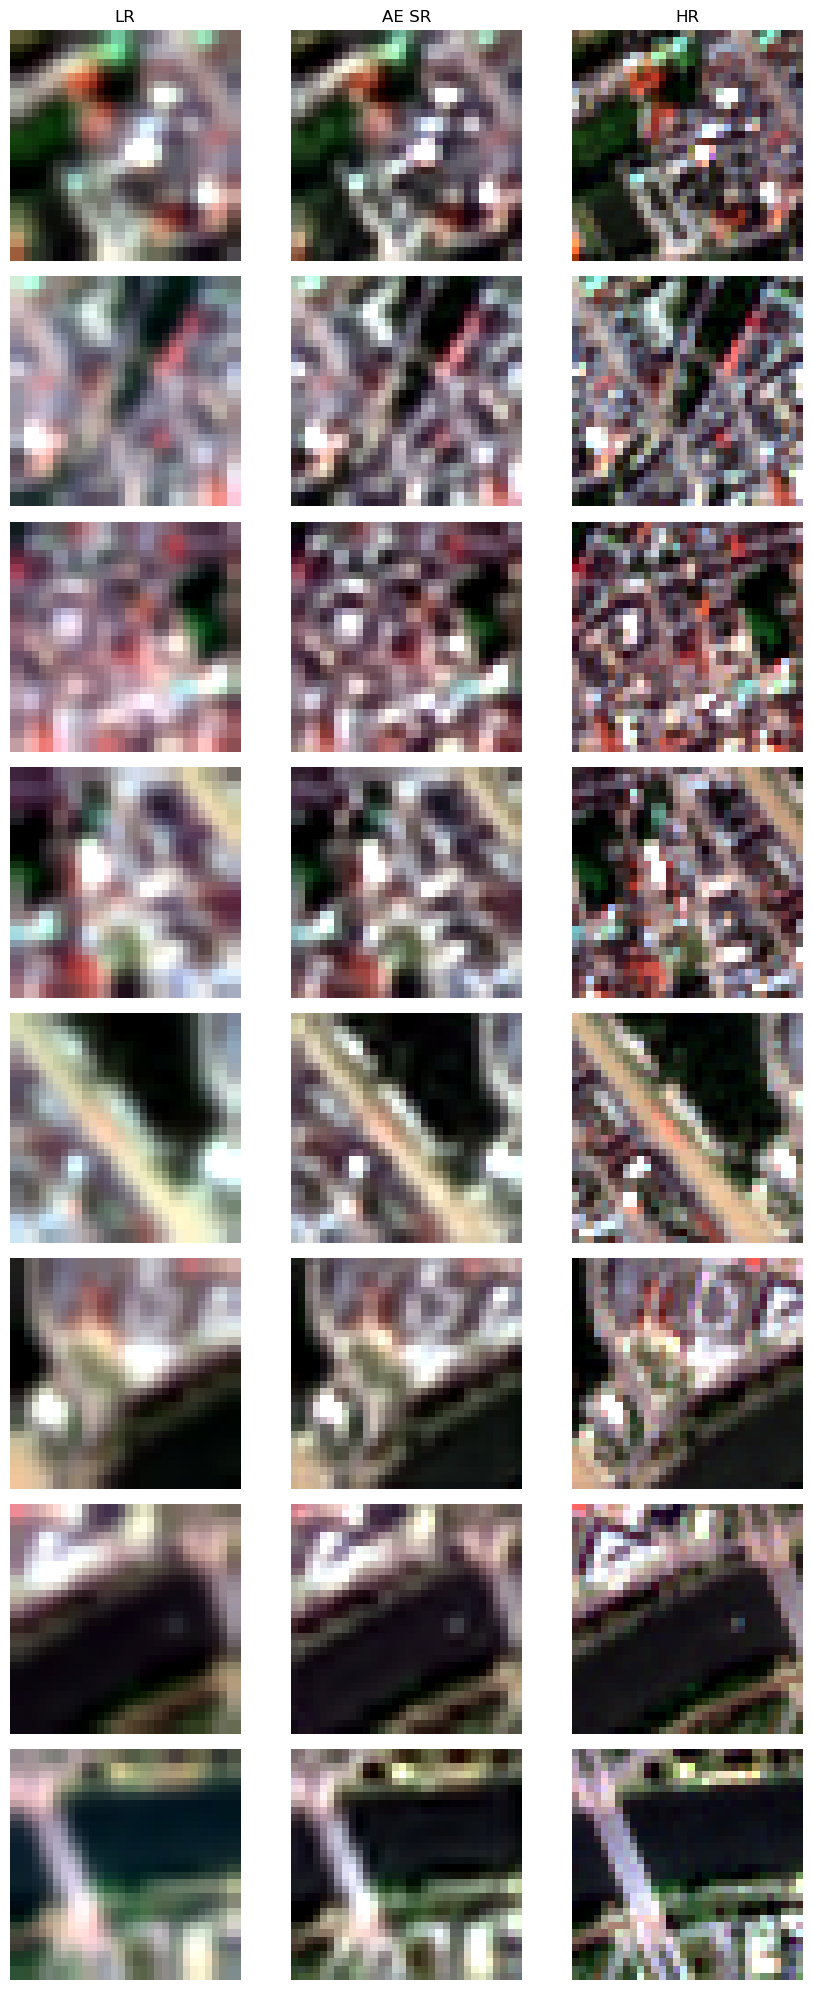

In [67]:
pred = np.clip(model.predict(x_val[:8], verbose=0), 0, 1)

fig, ax = plt.subplots(8, 3, figsize=(9, 20))
for i in range(8):
    ax[i, 0].imshow(to_rgb(x_val[i]))
    ax[i, 1].imshow(to_rgb(pred[i]))
    ax[i, 2].imshow(to_rgb(y_val[i]))
    for j, t in enumerate(["LR", "AE SR", "HR"]):
        if i == 0:
            ax[i, j].set_title(t)
        ax[i, j].axis("off")
plt.tight_layout()
plt.show()